In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib
from itertools import product
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit.library import real_amplitudes
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.quantum_info import Statevector, SparsePauliOp

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA as VCOBYLA

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer


# ==================================================
# 공통 Ground Truth 함수
# ==================================================

def exact_solution(problem):
    feasible = [
        np.array(bits, dtype=int)
        for bits in product([0, 1], repeat=problem.get_num_vars())
        if problem.is_feasible(np.array(bits))
    ]

    if not feasible:
        raise RuntimeError("실행 가능한 해가 없습니다.")

    best = min(
        feasible,
        key=lambda x: float(problem.objective.evaluate(x))
    )

    return best, float(problem.objective.evaluate(best))


def exact_min(problem):
    return exact_solution(problem)[1]


# ==================================================
# QNN 함수
# ==================================================

def run_qnn(problem, title, seed=42):
    rng = np.random.default_rng(seed)
    n = problem.get_num_vars()

    if n != 5:
        raise ValueError("현재 QNN은 5개 후보용입니다.")

    names = [v.name for v in problem.variables]
    truth, exact = exact_solution(problem)

    if not np.isclose(truth.sum(), 1):
        raise ValueError("하나의 후보를 선택하는 문제여야 합니다.")

    target = int(np.argmax(truth))

    costs = np.array([
        float(problem.objective.evaluate(np.eye(n, dtype=int)[i]))
        for i in range(n)
    ])

    x_input = (costs - costs.min()) / (np.ptp(costs) + 1e-8)

    ansatz = real_amplitudes(
        n, reps=2, entanglement="linear"
    )

    observables = []
    for i in range(n):
        pauli = ["I"] * n
        pauli[n - i - 1] = "Z"
        observables.append(SparsePauliOp("".join(pauli)))

    def forward(theta):
        qc = QuantumCircuit(n)

        for i in range(n):
            qc.ry(np.pi * x_input[i], i)

        qc.compose(ansatz.assign_parameters(theta), inplace=True)

        state = Statevector.from_instruction(qc)

        outputs = np.array([
            (1 - np.real(state.expectation_value(obs))) / 2
            for obs in observables
        ])

        logits = outputs * 10
        logits -= np.max(logits)
        exp_values = np.exp(logits)
        return exp_values / exp_values.sum()

    history = []
    accuracy_history = []

    def loss_fn(theta):
        probs = forward(theta)
        loss = -np.log(probs[target] + 1e-12)
        accuracy = int(np.argmax(probs) == target)

        history.append(float(loss))
        accuracy_history.append(accuracy)

        return float(loss)

    theta0 = rng.uniform(-1, 1, ansatz.num_parameters)

    opt_result = minimize(
        loss_fn,
        theta0,
        method="COBYLA",
        options={"maxiter": 200}
    )

    probabilities = forward(opt_result.x)
    predicted = int(np.argmax(probabilities))

    chosen = np.zeros(n, dtype=int)
    chosen[predicted] = 1

    value = float(problem.objective.evaluate(chosen))

    print("\n========== QNN 계산 결과 ==========")
    print("선택 비트:", chosen)
    print("선택 후보:", names[predicted])
    print("Ground Truth:", names[target])
    print("선택 비용:", value)
    print("정확한 최솟값:", exact)
    print("비용 차이:", value - exact)
    print("정답 여부:", predicted == target)
    print("최종 손실:", -np.log(probabilities[target] + 1e-12))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history)
    axes[0].set_title(title + " - 학습 손실")
    axes[0].set_xlabel("목적함수 평가 횟수")
    axes[0].set_ylabel("Cross Entropy")
    axes[0].grid(alpha=0.3)

    axes[1].plot(accuracy_history)
    axes[1].set_title(title + " - 정답 여부")
    axes[1].set_xlabel("목적함수 평가 횟수")
    axes[1].set_ylabel("Correct (0/1)")
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
    plt.close()

    plt.figure(figsize=(9, 4))
    plt.bar(names, probabilities)
    plt.title(title + " - 후보별 분류 확률")
    plt.ylabel("Softmax Probability")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    plt.close()

    return {
        "x": chosen,
        "fval": value,
        "history": history,
        "accuracy": accuracy_history,
        "probabilities": probabilities
    }


# ==================================================
# VQE 함수
# ==================================================

def run_vqe(problem, title, seed=42):
    converter = QuadraticProgramToQubo()
    qubo = converter.convert(problem)
    H, offset = qubo.to_ising()
    n = qubo.get_num_vars()

    diagonal = np.real(np.diag(H.to_matrix())) + offset

    for i, value in enumerate(diagonal):
        bits = np.array([(i >> j) & 1 for j in range(n)])
        assert np.isclose(value, qubo.objective.evaluate(bits))

    ansatz = real_amplitudes(
        n, reps=2, entanglement="linear"
    )

    history = []

    vqe = VQE(
        StatevectorEstimator(),
        ansatz,
        VCOBYLA(maxiter=180),
        initial_point=np.random.default_rng(seed).uniform(
            -1, 1, ansatz.num_parameters
        ),
        callback=lambda k, p, value, meta:
            history.append(float(np.real(value)) + offset)
    )

    result = vqe.compute_minimum_eigenvalue(H)

    state = Statevector.from_instruction(
        ansatz.assign_parameters(result.optimal_parameters)
    )

    probabilities = state.probabilities()
    candidates = []

    for i, p in enumerate(probabilities):
        bits = np.array([(i >> j) & 1 for j in range(n)])
        x = np.asarray(converter.interpret(bits))

        if problem.is_feasible(x):
            candidates.append((float(p), x))

    if not candidates:
        raise RuntimeError("VQE 실행 가능한 후보가 없습니다.")

    probability, chosen = max(candidates, key=lambda item: item[0])
    value = float(problem.objective.evaluate(chosen))
    exact = exact_min(problem)

    print("\n========== VQE 계산 결과 ==========")
    print("선택 비트:", chosen.astype(int))
    print("기대 QUBO 비용:", float(np.real(result.eigenvalue)) + offset)
    print("선택 비용:", value)
    print("정확한 최솟값:", exact)
    print("비용 차이:", value - exact)
    print("선택 상태 확률:", probability)

    plt.figure(figsize=(8, 4))
    plt.plot(history)
    plt.axhline(exact, linestyle="--", label="Ground Truth")
    plt.title(title + " - 에너지 수렴")
    plt.xlabel("목적함수 평가 횟수")
    plt.ylabel("기대 QUBO 비용")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    return {
        "x": chosen,
        "fval": value,
        "history": history,
        "probability": probability
    }


# ==================================================
# QAOA 함수
# ==================================================

def run_qaoa(problem, title, seed=42):
    history = []

    qaoa = QAOA(
        StatevectorSampler(default_shots=2048, seed=seed),
        COBYLA(maxiter=70),
        reps=1,
        initial_point=np.random.default_rng(seed).uniform(0.1, 1, 2),
        callback=lambda n, p, value, meta:
            history.append(float(np.real(value)))
    )

    result = MinimumEigenOptimizer(qaoa).solve(problem)

    if result.x is None or not problem.is_feasible(result.x):
        raise RuntimeError("QAOA 실행 가능한 해가 없습니다.")

    exact = exact_min(problem)

    mass = sum(
        float(s.probability)
        for s in result.samples
        if problem.is_feasible(s.x)
    )

    optimal_mass = sum(
        float(s.probability)
        for s in result.samples
        if problem.is_feasible(s.x)
        and np.isclose(s.fval, exact)
    )

    print("\n========== QAOA 계산 결과 ==========")
    print("선택 비트:", result.x.astype(int))
    print("선택 비용:", result.fval)
    print("정확한 최솟값:", exact)
    print("비용 차이:", result.fval - exact)
    print("실행 가능 관측 비율:", round(mass, 4))
    print("최적해 관측 비율:", round(optimal_mass, 4))

    plt.figure(figsize=(8, 4))
    plt.plot(history)
    plt.title(title + " - 에너지 수렴")
    plt.xlabel("목적함수 평가 횟수")
    plt.ylabel("Ising 기대 에너지")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    return {
        "x": result.x,
        "fval": float(result.fval),
        "history": history,
        "valid_mass": mass,
        "optimal_mass": optimal_mass
    }


print("QNN / VQE / QAOA 함수 선언 완료")


QNN / VQE / QAOA 함수 선언 완료



========== QNN 계산 결과 ==========
선택 비트: [0 1 0 0 0]
선택 후보: B_마포
Ground Truth: B_마포
선택 비용: 35.0
정확한 최솟값: 35.0
비용 차이: 0.0
정답 여부: True
최종 손실: 0.0001903478763529781


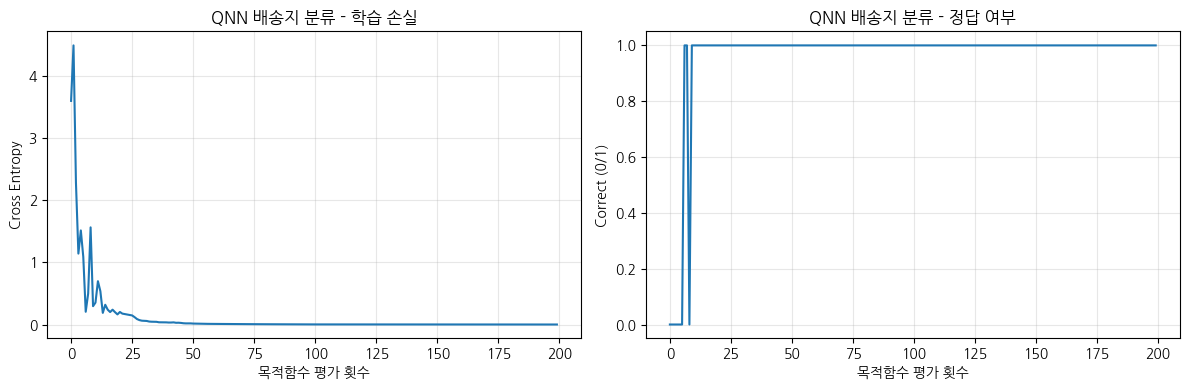

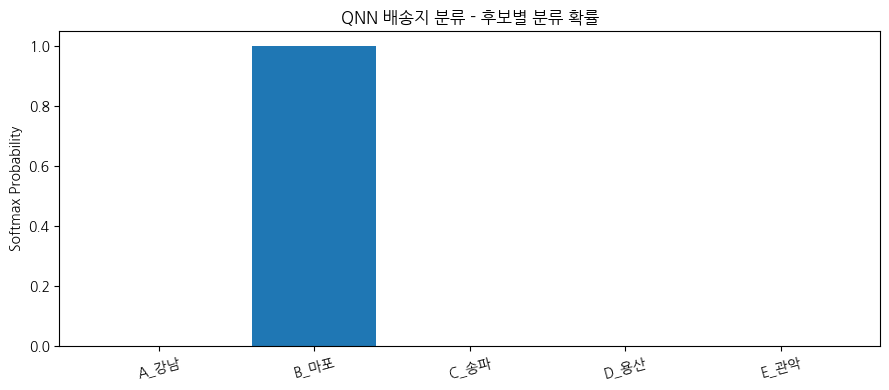


========== VQE 계산 결과 ==========
선택 비트: [1 0 0 0 0]
기대 QUBO 비용: 45.54308036197631
선택 비용: 45.0
정확한 최솟값: 35.0
비용 차이: 10.0
선택 상태 확률: 0.9981556649010302


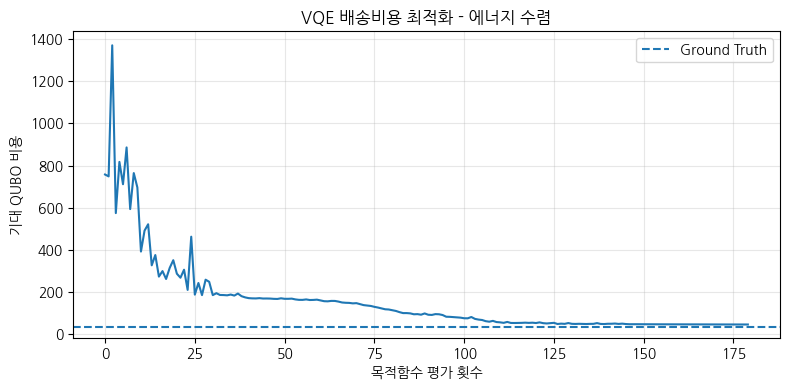


========== QAOA 계산 결과 ==========
선택 비트: [0 1 0 0 0]
선택 비용: 35.0
정확한 최솟값: 35.0
비용 차이: 0.0
실행 가능 관측 비율: 0.3745
최적해 관측 비율: 0.0591


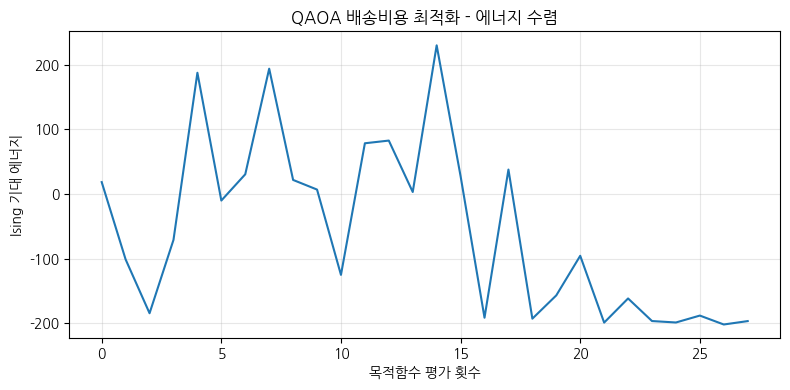


========== 최종 비교 결과 ==========
Ground Truth: B_마포
Ground Truth 최소비용: 35.0
QNN | 선택=B_마포 | 비용=35.0000 | 차이=0.0000
VQE | 선택=A_강남 | 비용=45.0000 | 차이=10.0000
QAOA | 선택=B_마포 | 비용=35.0000 | 차이=0.0000


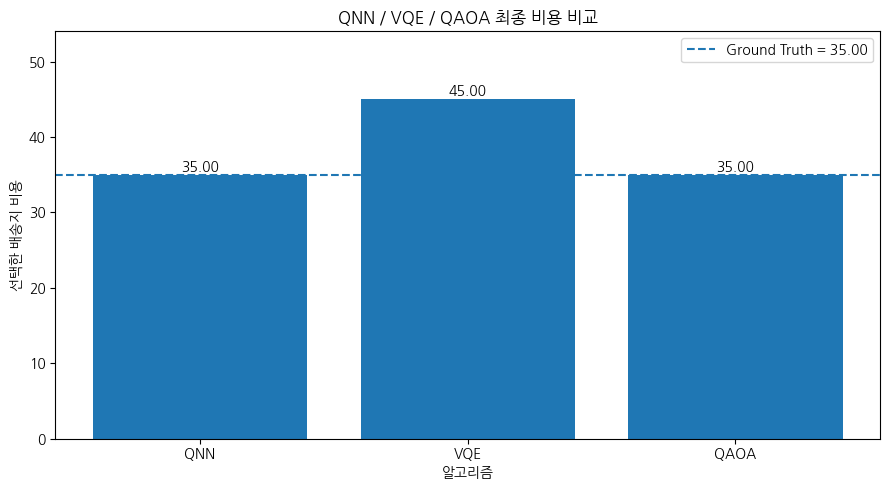

In [3]:

# ==================================================
# 최적화 문제 정의
# ==================================================

costs = {
    "A_강남": 45,
    "B_마포": 35,
    "C_송파": 52,
    "D_용산": 40,
    "E_관악": 48
}

problem = QuadraticProgram()

for name in costs:
    problem.binary_var(name)

problem.linear_constraint(
    {name: 1 for name in costs},
    "==", 1
)

problem.minimize(linear=costs)


# ==================================================
# QNN / VQE / QAOA 실행
# ==================================================

result_qnn = run_qnn(problem, "QNN 배송지 분류")
result_vqe = run_vqe(problem, "VQE 배송비용 최적화")
result_qaoa = run_qaoa(problem, "QAOA 배송비용 최적화")


# ==================================================
# 최종 결과 비교
# ==================================================

names = list(costs.keys())
truth_x, truth_cost = exact_solution(problem)

results = {
    "QNN": result_qnn,
    "VQE": result_vqe,
    "QAOA": result_qaoa
}

print("\n========== 최종 비교 결과 ==========")
print("Ground Truth:", names[int(np.argmax(truth_x))])
print("Ground Truth 최소비용:", truth_cost)

for name, res in results.items():
    selected_idx = int(np.argmax(res["x"]))

    print(
        f"{name} | "
        f"선택={names[selected_idx]} | "
        f"비용={res['fval']:.4f} | "
        f"차이={res['fval'] - truth_cost:.4f}"
    )


# ==================================================
# 최종 비교 그래프
# ==================================================

algorithms = ["QNN", "VQE", "QAOA"]
values = [results[name]["fval"] for name in algorithms]

plt.figure(figsize=(9, 5))
plt.bar(algorithms, values)

plt.axhline(
    truth_cost,
    linestyle="--",
    label=f"Ground Truth = {truth_cost:.2f}"
)

for i, value in enumerate(values):
    plt.text(i, value + 0.5, f"{value:.2f}", ha="center")

plt.title("QNN / VQE / QAOA 최종 비용 비교")
plt.xlabel("알고리즘")
plt.ylabel("선택한 배송지 비용")
plt.ylim(0, max(values) * 1.2)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()
